# Task 3: Deep learning with explainability (LSTM + SHAP)

**Goal:** predict the next hour's real traffic volume using an LSTM and examine a comparable Random Forest with SHAP. The target is observed traffic volume, not the proxy accident-risk label.

The LSTM consumes 24 hours of volume and weather; the Random Forest receives 24 volume lags, last-hour weather and target-hour calendar features. Both predict the same targets, but they have different inputs and fitting procedures. **SHAP explains the Random Forest only; similar accuracy does not establish that the LSTM uses the same signals.**

In [1]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PART_DIR = Path.cwd().resolve().parent
OUT = PART_DIR / "outputs"
pd.options.display.float_format = "{:,.3f}".format

## 1. Data preparation and evaluation

The script uses consecutive 24-hour windows only and a chronological 80/20 split. The last 10% of pre-test windows is validation. Weather imputation and standardization are fitted strictly before the first validation target; the original CSV restores weather values that were imputed upstream. The target-hour calendar must be known at prediction time.

This notebook **reads** the existing output files and does not train models or overwrite artifacts. First run `python Part-3/lstm_model.py` from the repository root to regenerate all outputs and MLflow runs together.

In [2]:
info = json.loads((OUT / "lstm_run_info.json").read_text(encoding="utf-8"))
metrics = pd.read_csv(OUT / "lstm_metrics.csv")
groups = pd.read_csv(OUT / "shap_family_importance.csv")
pd.Series({k: info[k] for k in ("n_windows", "n_train", "n_validation", "n_forest_train",
                                 "n_test", "n_test_rows", "test_start", "epochs_run")})

n_windows                       28871
n_train                         19067
n_validation                     2118
n_forest_train                  21185
n_test                           7686
n_test_rows                      8115
test_start        2017-10-26 18:00:00
epochs_run                         60
dtype: object

## 2. The LSTM

The sequence has 24 steps and five features. An LSTM with 64 units and dropout is joined with six target-hour calendar features, followed by a dense layer and one output. Early stopping selects weights using the validation period. Predictions are inverse-scaled and clipped to zero to prevent physically impossible negative traffic volumes.

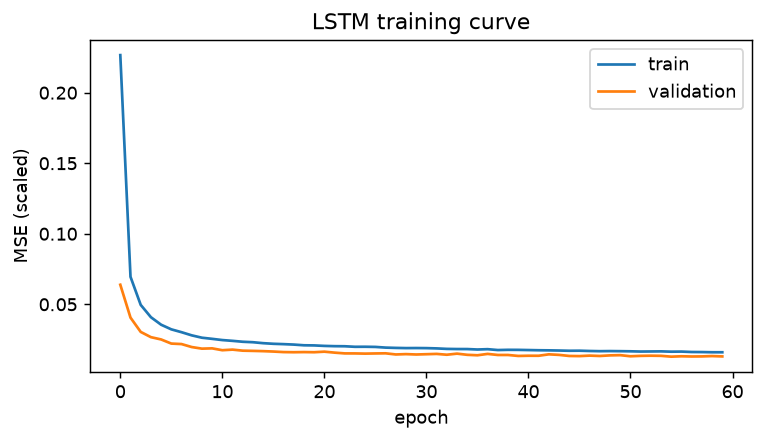

In [3]:
display(Image(filename=str(OUT / "lstm_training_curve.png")))

## 3. Test-period accuracy

Every model is scored on the same eligible test targets. MAE and RMSE are in vehicles/hour; lower is better. Persistence repeats the previous hour; the second baseline repeats the same hour yesterday. The forest trains on all pre-test windows; the LSTM reserves a validation tail.

In [4]:
metrics.set_index("model")

,MAE,RMSE,R2
model,,,
Baseline: persistence (previous hour),585.333,811.831,0.830
Baseline: same hour yesterday,571.579,"1,030.827",0.726
"Random Forest (lag features, SHAP twin)",147.320,234.133,0.986
Random Forest (calendar + weather only),271.259,448.030,0.948
LSTM,155.157,235.217,0.986


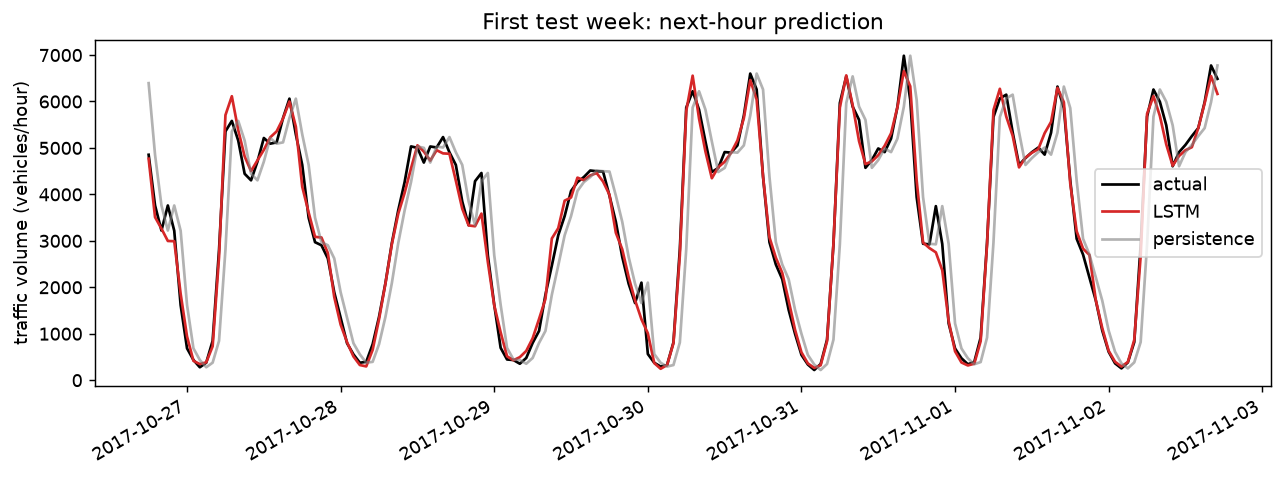

In [5]:
display(Image(filename=str(OUT / "lstm_test_week.png")))

The metrics compare predictive performance on one test period; they do not prove that either model uses a particular feature or that either will generalize to other periods. Forests train on more windows because the LSTM holds out validation for early stopping.

## 4. SHAP for the Random Forest

SHAP gives feature contributions relative to the forest's expected output. Global importance is mean absolute SHAP over a sample of up to 500 eligible test windows. Percentage shares depend on this model, sample, and correlated features; they are not causal effects and do not explain the LSTM.

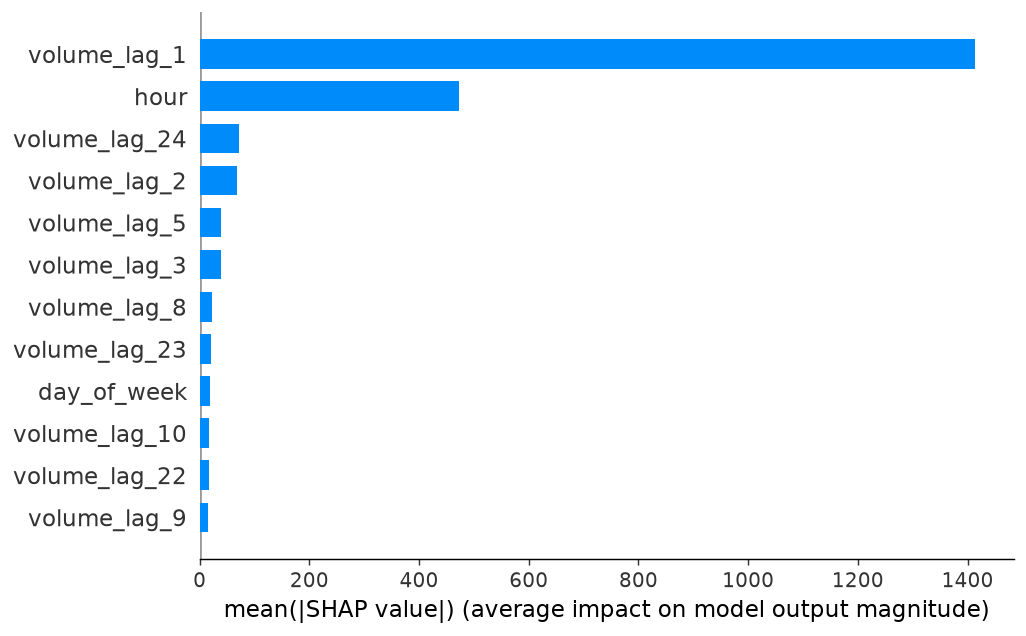

,mean_abs_shap,share
group,,
volume lag 1 (previous hour),"1,413.619",0.607
calendar,501.314,0.215
volume lags 7-24,242.798,0.104
volume lags 2-6,164.680,0.071
weather,6.801,0.003


In [6]:
display(Image(filename=str(OUT / "shap_summary_bar.png")))
groups.set_index("group")

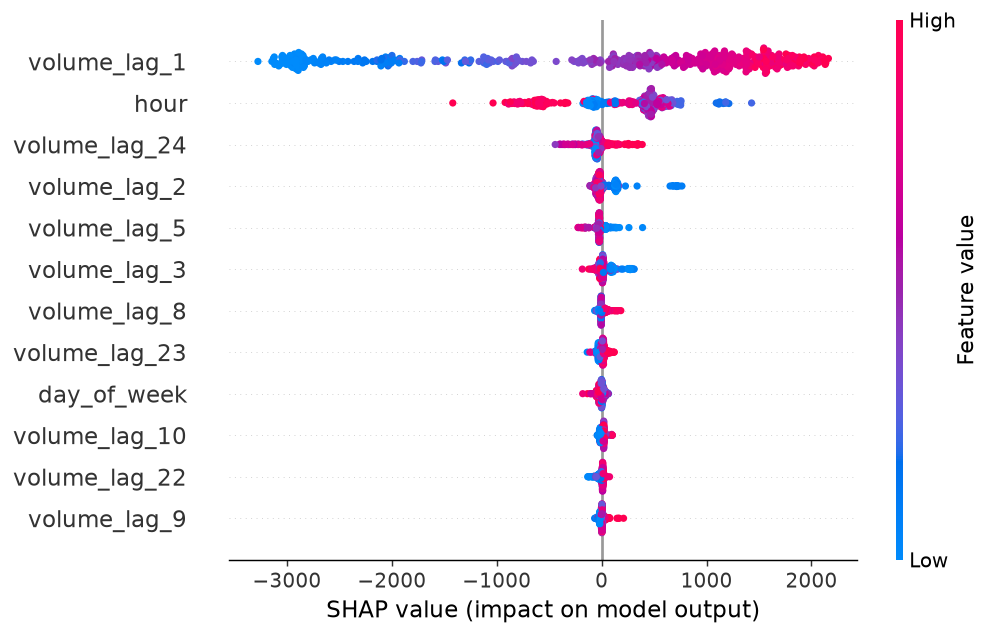

In [7]:
display(Image(filename=str(OUT / "shap_beeswarm.png")))

The beeswarm shows each sampled forest prediction's feature contributions. A high or low attribution describes this fitted forest, not the LSTM or a causal weather effect. The forest uses only previous-hour numerical weather. In this dataset `snow_1h` has no variation in the forest's training windows, so its attribution cannot establish that snow has no effect; the snow weather category is not a forest input.

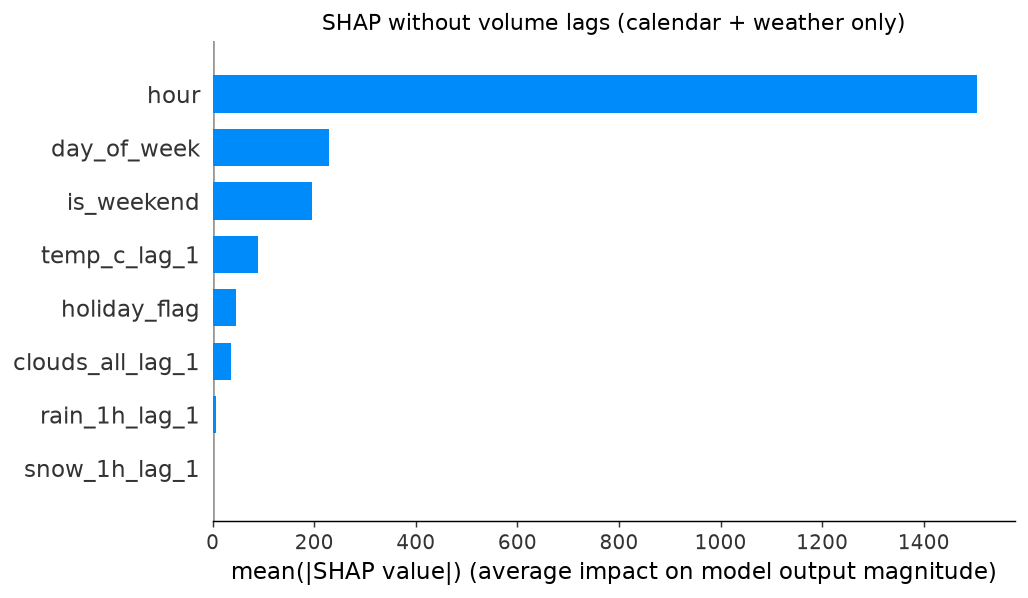

In [8]:
display(Image(filename=str(OUT / "shap_bar_no_lags.png")))

### Individual forest predictions

Each waterfall starts at the forest's expected output and adds feature contributions. The two examples are selected from the test sample (weekday 07:00 and 03:00); they describe those individual forest predictions only.

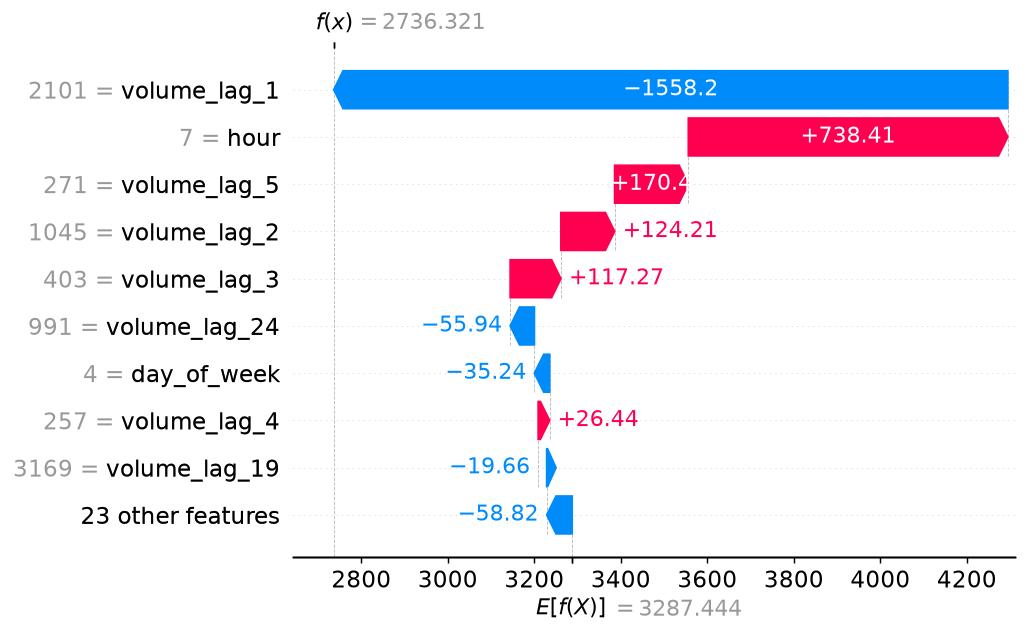

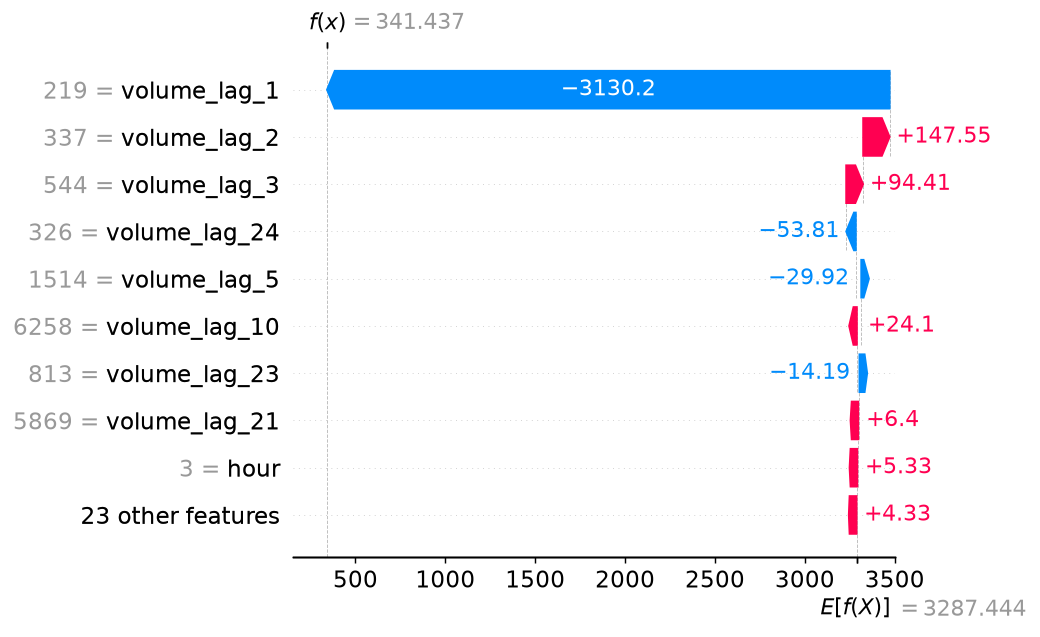

In [9]:
display(Image(filename=str(OUT / "shap_local_weekday_rush_hour.png")))
display(Image(filename=str(OUT / "shap_local_night.png")))

## 5. MLflow runs

The script records one run per model or baseline, with the appropriate fitted training count. The LSTM run contains metrics, preprocessing metadata, model and plots; each forest run contains its own fitted forest. The table shows the latest recorded run of each name, which corresponds to the latest script run only when MLflow logging is enabled.

In [10]:
import mlflow

mlflow.set_tracking_uri(f"sqlite:///{(PART_DIR / 'mlflow.db').as_posix()}")
runs = mlflow.search_runs(experiment_names=["task3-deep-learning"])
latest = runs.sort_values("start_time", ascending=False).drop_duplicates("tags.mlflow.runName")
latest.set_index("tags.mlflow.runName")[[c for c in latest.columns if c.startswith("metrics.") or c == "params.n_train"]]

,metrics.R2,metrics.RMSE,metrics.MAE,params.n_train
tags.mlflow.runName,,,,
LSTM,0.986,235.217,155.157,19067
Random Forest (calendar + weather only),0.948,448.030,271.259,21185
"Random Forest (lag features, SHAP twin)",0.986,234.133,147.320,21185
Baseline: same hour yesterday,0.726,"1,030.827",571.579,0
Baseline: persistence (previous hour),0.830,811.831,585.333,0


## 6. Limitations

- Evaluation includes only hours with a full consecutive 24-hour history; it does not assess predictions immediately after gaps. See the counts above.
- SHAP describes the forest only. Weather attribution is conditional on its inputs and sample and is not causal.
- The LSTM needs recent hourly observations; using predictions recursively for longer horizons is not evaluated.
- This is one chronological split and one random seed; year coverage is uneven. The holiday flag assumes the target date's holiday information is available at prediction time.
- Model and metadata files should be kept together; joblib files must only be loaded from trusted sources.